In [1]:
import importlib.util
import subprocess
import sys
from pathlib import Path

package_modules = {
    "datasets": "datasets",
    "pandas": "pandas",
    "scikit-learn": "sklearn",
    "matplotlib": "matplotlib",
    "joblib": "joblib"
}

missing = [package for package, module in package_modules.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

current_dir = Path.cwd()
if current_dir.name.lower() == "notebooks":
    PROJECT_ROOT = current_dir.parent
elif (current_dir / "notebooks").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "notebooks").exists():
    PROJECT_ROOT = current_dir.parent
else:
    PROJECT_ROOT = current_dir

DATA_DIR = PROJECT_ROOT / "data" / "amazon_product_reviews"
MODEL_DIR = PROJECT_ROOT / "models" / "nlp"
REPORT_DIR = PROJECT_ROOT / "reports" / "day12_nlp"
SRC_DIR = PROJECT_ROOT / "src"

for folder in [DATA_DIR, MODEL_DIR, REPORT_DIR, SRC_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_ROOT)
print("Review data:", DATA_DIR)

c:\Users\rupam\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project: c:\Users\rupam\OneDrive\Desktop\Retail_Mind
Review data: c:\Users\rupam\OneDrive\Desktop\Retail_Mind\data\amazon_product_reviews


In [2]:
from pathlib import Path
import sys
import importlib

module_code = 'import html\nimport re\nfrom pathlib import Path\n\nimport joblib\nfrom sklearn.feature_extraction.text import ENGLISH_STOP_WORDS\n\nSTOP_WORDS = set(ENGLISH_STOP_WORDS)\n\n\ndef tokenize_review(text):\n    text = html.unescape(str(text)).lower()\n    text = re.sub(r"<[^>]+>", " ", text)\n    text = re.sub(r"https?://\\S+|www\\.\\S+", " ", text)\n    text = re.sub(r"[^a-z\']", " ", text)\n    tokens = re.findall(r"[a-z]+(?:\'[a-z]+)?", text)\n    return [token for token in tokens if len(token) > 2 and token not in STOP_WORDS]\n\n\ndef clean_review_text(text):\n    return " ".join(tokenize_review(text))\n\n\ndef predict_review_sentiment(review_text, model_path=None):\n    project_root = Path(__file__).resolve().parents[1]\n    if model_path is None:\n        model_path = project_root / "models" / "nlp" / "retailmind_sentiment_pipeline.joblib"\n    pipeline = joblib.load(model_path)\n    prediction = int(pipeline.predict([review_text])[0])\n    probabilities = pipeline.predict_proba([review_text])[0]\n    return {\n        "sentiment": "positive" if prediction == 1 else "negative",\n        "label": prediction,\n        "confidence": float(max(probabilities))\n    }\n'
module_path = SRC_DIR / "review_processor.py"
module_path.write_text(module_code, encoding="utf-8")

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import review_processor
importlib.reload(review_processor)

print("Review processing module created:", module_path)

Review processing module created: c:\Users\rupam\OneDrive\Desktop\Retail_Mind\src\review_processor.py


In [3]:
DATASET_NAME = "fancyzhx/amazon_polarity"
SAMPLE_PER_SENTIMENT = 5000
FORCE_DOWNLOAD = False

reviews_path = DATA_DIR / "amazon_reviews_sample.csv"

if reviews_path.exists() and not FORCE_DOWNLOAD:
    reviews = pd.read_csv(reviews_path)
    print("Using existing review sample:", reviews_path)
else:
    print("Streaming Amazon Polarity reviews from Hugging Face...")
    review_stream = load_dataset(DATASET_NAME, split="train", streaming=True)
    review_stream = review_stream.shuffle(seed=42, buffer_size=20000)

    collected = {0: [], 1: []}
    max_rows_to_read = 80000

    for index, row in enumerate(review_stream):
        label = int(row["label"])
        if label in collected and len(collected[label]) < SAMPLE_PER_SENTIMENT:
            title = str(row.get("title", "")).strip()
            content = str(row.get("content", "")).strip()
            review_text = (title + " " + content).strip()
            if review_text:
                collected[label].append({
                    "review_text": review_text,
                    "label": label,
                    "sentiment": "positive" if label == 1 else "negative"
                })

        if all(len(collected[label]) >= SAMPLE_PER_SENTIMENT for label in collected):
            break
        if index + 1 >= max_rows_to_read:
            break

    if min(len(collected[0]), len(collected[1])) == 0:
        raise ValueError("No reviews were downloaded. Check your internet connection and dataset access.")

    if min(len(collected[0]), len(collected[1])) < SAMPLE_PER_SENTIMENT:
        print("The stream ended before the requested sample size. Using the reviews collected.")

    reviews = pd.DataFrame(collected[0] + collected[1])
    reviews = reviews.sample(frac=1, random_state=42).reset_index(drop=True)
    reviews.to_csv(reviews_path, index=False)
    print("Saved review sample:", reviews_path)

print("Review rows:", len(reviews))
print(reviews["sentiment"].value_counts())

Using existing review sample: c:\Users\rupam\OneDrive\Desktop\Retail_Mind\data\amazon_product_reviews\amazon_reviews_sample.csv
Review rows: 10000
sentiment
positive    5000
negative    5000
Name: count, dtype: int64


In [4]:
reviews = reviews.dropna(subset=["review_text", "label"]).copy()
reviews["review_text"] = reviews["review_text"].astype(str).str.strip()
reviews["label"] = reviews["label"].astype(int)
reviews = reviews[reviews["review_text"].str.len() > 0]
reviews = reviews[reviews["label"].isin([0, 1])].reset_index(drop=True)
reviews["sentiment"] = reviews["label"].map({0: "negative", 1: "positive"})

print(reviews.head(5))
print("\nClass distribution")
print(reviews["sentiment"].value_counts())

reviews["review_length"] = reviews["review_text"].str.split().str.len()
print(reviews["review_length"].describe())

                                         review_text  label sentiment
0  Provides a great foundation for further studie...      1  positive
1  World's most expensive disposable razor This s...      0  negative
2  Forget this one Watch the first two and forget...      0  negative
3  Greenwood goes megalomaniac again Oh no. Anoth...      0  negative
4  Loss of Faith It's amazing how poorly this boo...      0  negative

Class distribution
sentiment
positive    5000
negative    5000
Name: count, dtype: int64
count    10000.000000
mean        77.466100
std         42.812649
min          8.000000
25%         41.000000
50%         69.000000
75%        106.000000
max        204.000000
Name: review_length, dtype: float64


In [5]:
from review_processor import tokenize_review, clean_review_text

reviews["clean_text"] = reviews["review_text"].apply(clean_review_text)
reviews = reviews[reviews["clean_text"].str.len() > 0].reset_index(drop=True)

print("Original review:")
print(reviews.loc[0, "review_text"][:500])
print("\nCleaned review:")
print(reviews.loc[0, "clean_text"][:500])

Original review:
Provides a great foundation for further studies. This is a very handy little book. It answered many fundamental questions I had about the Buddhist philosophy. The book helped me to realize that I am a Buddhist - no matter where I am in my path.

Cleaned review:
provides great foundation studies handy little book answered fundamental questions buddhist philosophy book helped realize buddhist matter path


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    reviews["review_text"],
    reviews["label"],
    test_size=0.2,
    random_state=42,
    stratify=reviews["label"]
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

Training reviews: 8000
Testing reviews: 2000


In [7]:
vectorizer = TfidfVectorizer(
    tokenizer=tokenize_review,
    preprocessor=None,
    token_pattern=None,
    lowercase=False,
    max_features=25000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

Training matrix: (8000, 25000)
Testing matrix: (2000, 25000)


In [8]:
classifier = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42,
    solver="liblinear"
)

classifier.fit(X_train_tfidf, y_train)
y_pred = classifier.predict(X_test_tfidf)

print("Sentiment classifier training completed.")

Sentiment classifier training completed.


Evaluation metrics
accuracy: 0.8660
precision: 0.8617
recall: 0.8720
f1_score: 0.8668

Classification report
              precision    recall  f1-score   support

    Negative       0.87      0.86      0.87      1000
    Positive       0.86      0.87      0.87      1000

    accuracy                           0.87      2000
   macro avg       0.87      0.87      0.87      2000
weighted avg       0.87      0.87      0.87      2000



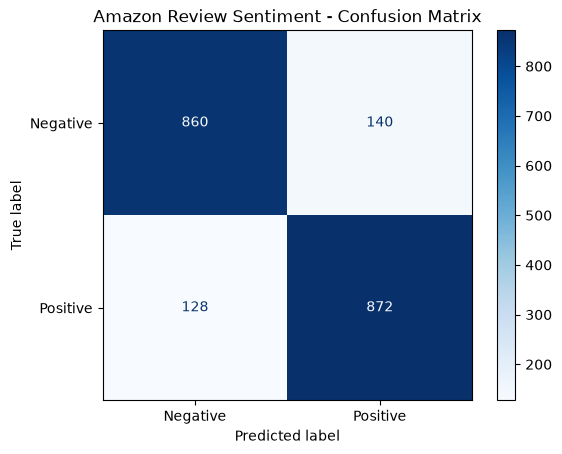

In [9]:
metrics = {
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "precision": float(precision_score(y_test, y_pred, zero_division=0)),
    "recall": float(recall_score(y_test, y_pred, zero_division=0)),
    "f1_score": float(f1_score(y_test, y_pred, zero_division=0))
}

print("Evaluation metrics")
for name, value in metrics.items():
    print(f"{name}: {value:.4f}")

print("\nClassification report")
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"], zero_division=0))

cm = confusion_matrix(y_test, y_pred)
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])
cm_display.plot(cmap="Blues", values_format="d")
plt.title("Amazon Review Sentiment - Confusion Matrix")
plt.show()

In [10]:
feature_names = np.array(vectorizer.get_feature_names_out())
coefficients = classifier.coef_[0]

positive_indices = np.argsort(coefficients)[-20:][::-1]
negative_indices = np.argsort(coefficients)[:20]

positive_terms = pd.DataFrame({
    "term": feature_names[positive_indices],
    "weight": coefficients[positive_indices]
})
negative_terms = pd.DataFrame({
    "term": feature_names[negative_indices],
    "weight": coefficients[negative_indices]
})

print("Most informative positive terms")
display(positive_terms)
print("Most informative negative terms")
display(negative_terms)

Most informative positive terms


,term,weight
0,great,8.606698
1,excellent,5.187418
2,best,5.084070
3,love,4.953334
4,good,4.228017
5,easy,3.355759
6,perfect,3.343161
7,wonderful,3.114617
8,favorite,3.053757
9,awesome,2.833665


Most informative negative terms


,term,weight
0,boring,-4.334463
1,bad,-4.236996
2,disappointed,-4.204688
3,worst,-4.158205
4,waste,-4.150841
5,disappointing,-3.754898
6,terrible,-3.716652
7,poor,-3.652387
8,money,-3.322133
9,horrible,-3.275787


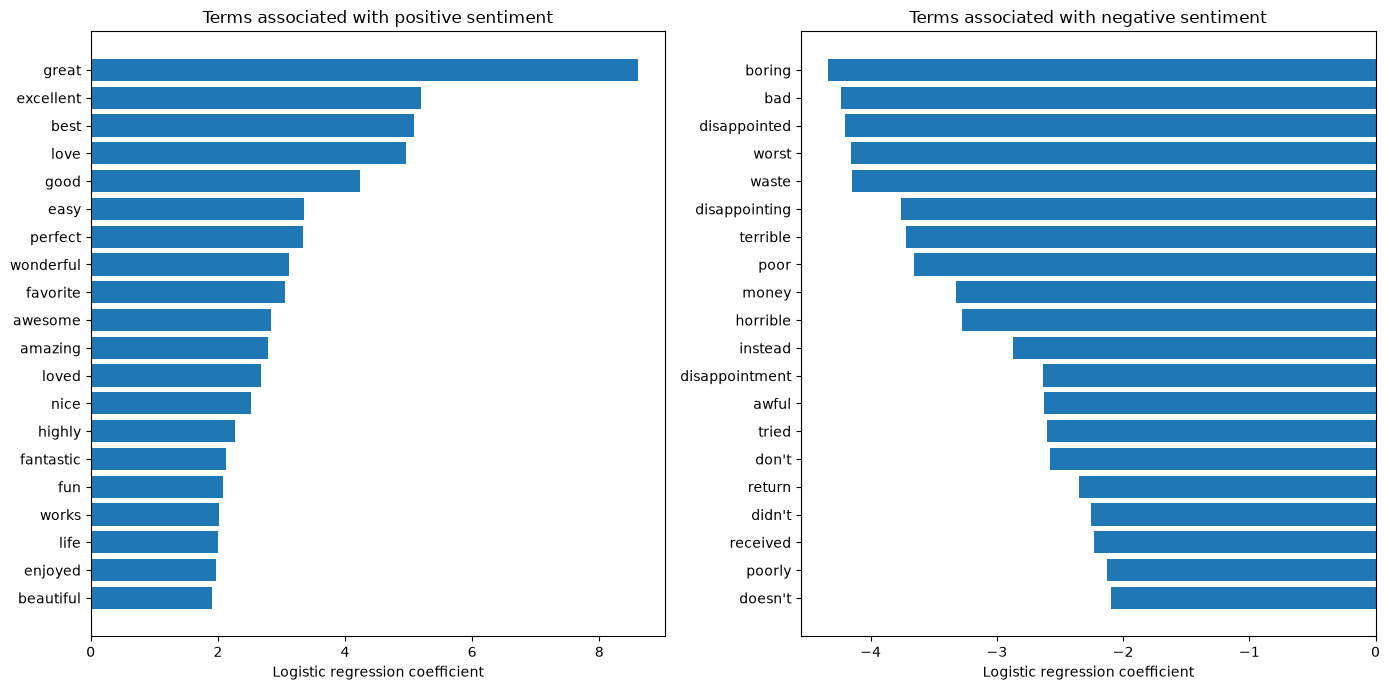

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].barh(positive_terms["term"][::-1], positive_terms["weight"][::-1])
axes[0].set_title("Terms associated with positive sentiment")
axes[0].set_xlabel("Logistic regression coefficient")

axes[1].barh(negative_terms["term"][::-1], negative_terms["weight"][::-1])
axes[1].set_title("Terms associated with negative sentiment")
axes[1].set_xlabel("Logistic regression coefficient")

plt.tight_layout()
plt.show()

In [12]:
pipeline = Pipeline([
    ("tfidf", vectorizer),
    ("classifier", classifier)
])

model_path = MODEL_DIR / "retailmind_sentiment_pipeline.joblib"
metrics_path = REPORT_DIR / "sentiment_metrics.json"
terms_path = REPORT_DIR / "informative_terms.csv"

joblib.dump(pipeline, model_path)

with open(metrics_path, "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=4)

terms = pd.concat([
    positive_terms.assign(sentiment="positive"),
    negative_terms.assign(sentiment="negative")
], ignore_index=True)
terms.to_csv(terms_path, index=False)

print("Saved model:", model_path)
print("Saved metrics:", metrics_path)
print("Saved informative terms:", terms_path)

Saved model: c:\Users\rupam\OneDrive\Desktop\Retail_Mind\models\nlp\retailmind_sentiment_pipeline.joblib
Saved metrics: c:\Users\rupam\OneDrive\Desktop\Retail_Mind\reports\day12_nlp\sentiment_metrics.json
Saved informative terms: c:\Users\rupam\OneDrive\Desktop\Retail_Mind\reports\day12_nlp\informative_terms.csv


In [13]:
from review_processor import predict_review_sentiment

examples = [
    "This product is excellent. The quality is great and I am very happy with it.",
    "Terrible quality. It stopped working quickly and I regret buying it."
]

for example in examples:
    result = predict_review_sentiment(example, model_path=model_path)
    print("Review:", example)
    print("Prediction:", result)
    print()

Review: This product is excellent. The quality is great and I am very happy with it.
Prediction: {'sentiment': 'positive', 'label': 1, 'confidence': 0.9200991893860891}

Review: Terrible quality. It stopped working quickly and I regret buying it.
Prediction: {'sentiment': 'negative', 'label': 0, 'confidence': 0.8736156241472894}

